# Tratamento dos dados: 2º turno presidencial por município

Como a base usada pela aplicação foi montada a partir dos dados abertos do **TSE** e do **IBGE**. O processo completo está em `scripts/gerar_dataset.py`; aqui as etapas principais aparecem uma a uma, com os mesmos comandos vistos em aula.

> Antes de rodar, execute `python scripts/gerar_dataset.py` na raiz do projeto: ele baixa os arquivos brutos para `data/raw/`.

In [1]:
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 1. Base bruta do TSE

Arquivo `detalhe_votacao_munzona_2026`: uma linha por município, zona eleitoral, turno e cargo.

In [2]:
# O TSE publica o CSV dentro de um zip, em latin-1 e separado por ponto e vírgula
arquivo_zip = zipfile.ZipFile("../data/raw/detalhe_votacao_munzona_2026.zip")
df_bruto = pd.read_csv(arquivo_zip.open("detalhe_votacao_munzona_2026_BRASIL.csv"), sep=";", encoding="latin-1")
df_bruto.shape

(37521, 47)

In [3]:
df_bruto.head()

,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,...,QT_TOTAL_VOTOS_ANUL_SUBJUD,QT_VOTOS_NOMINAIS_ANUL_SUBJUD,QT_VOTOS_LEGENDA_ANUL_SUBJUD,QT_VOTOS_BRANCOS,QT_TOTAL_VOTOS_NULOS,QT_VOTOS_NULOS,QT_VOTOS_NULOS_TECNICOS,QT_VOTOS_ANULADOS_APU_SEP,HH_ULTIMA_TOTALIZACAO,DT_ULTIMA_TOTALIZACAO
0,11/11/2026,05:32:18,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,3,3,0,265,202,202,0,0,19:25:32,04/10/2026
1,11/11/2026,05:32:18,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,0,0,0,141,158,158,0,0,20:58:20,04/10/2026
2,11/11/2026,05:32:18,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,0,0,0,458,381,380,1,0,10:13:22,10/10/2026
3,11/11/2026,05:32:18,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,0,0,0,343,637,634,3,0,20:58:15,04/10/2026
4,11/11/2026,05:32:18,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,0,0,0,15,90,90,0,0,10:13:22,10/10/2026


In [4]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 37521 entries, 0 to 37520
Data columns (total 47 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   DT_GERACAO                          37521 non-null  str  
 1   HH_GERACAO                          37521 non-null  str  
 2   ANO_ELEICAO                         37521 non-null  int64
 3   CD_TIPO_ELEICAO                     37521 non-null  int64
 4   NM_TIPO_ELEICAO                     37521 non-null  str  
 5   NR_TURNO                            37521 non-null  int64
 6   CD_ELEICAO                          37521 non-null  int64
 7   DS_ELEICAO                          37521 non-null  str  
 8   DT_ELEICAO                          37521 non-null  str  
 9   TP_ABRANGENCIA                      37521 non-null  str  
 10  SG_UF                               37521 non-null  str  
 11  SG_UE                               37521 non-null  str  
 12  NM_UE          

In [5]:
df_bruto[["NR_TURNO", "DS_CARGO"]].value_counts()

NR_TURNO  DS_CARGO          
1         Presidente            6292
2         Presidente            6292
1         Deputado Federal      6106
          Senador               6106
          Governador            6106
          Deputado Estadual     6087
2         Governador             513
1         Deputado Distrital      19
Name: count, dtype: int64

## 2. Filtrar as linhas

Só o 2º turno, só o cargo de presidente e sem as seções do exterior (UF `ZZ`).

In [6]:
# Cargo 1 = Presidente
filtro = (df_bruto["NR_TURNO"] == 2) & (df_bruto["CD_CARGO"] == 1) & (df_bruto["SG_UF"] != "ZZ")
df = df_bruto[filtro]
df.shape

(6106, 47)

## 3. Remover os campos que não serão usados

Das 47 colunas, ficam só as que identificam o município e as quantidades usadas nos indicadores.

In [7]:
colunas_usadas = [
    "SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO", "QT_APTOS", "QT_COMPARECIMENTO",
    "QT_ABSTENCOES", "QT_VOTOS_BRANCOS", "QT_TOTAL_VOTOS_NULOS",
]
colunas_removidas = [coluna for coluna in df.columns if coluna not in colunas_usadas]
df = df.drop(columns=colunas_removidas)
print("Colunas removidas:", len(colunas_removidas))
df.head()

Colunas removidas: 39


,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,QT_APTOS,QT_COMPARECIMENTO,QT_ABSTENCOES,QT_VOTOS_BRANCOS,QT_TOTAL_VOTOS_NULOS
35,PB,21830,SÃO JOÃO DO TIGRE,3965,3361,604,36,82
36,PE,24252,GRANITO,6957,5916,1041,41,88
37,GO,93343,ÁGUAS LINDAS DE GOIÁS,125182,101291,23891,1370,1394
44,ES,56006,SÃO DOMINGOS DO NORTE,8443,6860,1583,80,195
45,ES,56693,MONTANHA,15423,11968,3455,151,436


In [8]:
# Verificando ausentes e duplicados
print(df.isnull().sum())
print("Duplicados:", df.duplicated().sum())

SG_UF                   0
CD_MUNICIPIO            0
NM_MUNICIPIO            0
QT_APTOS                0
QT_COMPARECIMENTO       0
QT_ABSTENCOES           0
QT_VOTOS_BRANCOS        0
QT_TOTAL_VOTOS_NULOS    0
dtype: int64
Duplicados: 0


## 4. Agrupar as zonas de cada município

Um município grande tem várias zonas eleitorais: as quantidades de cada zona são somadas.

In [9]:
por_municipio = df.groupby(["SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO"]).agg(
    eleitores=("QT_APTOS", "sum"),
    abstencoes=("QT_ABSTENCOES", "sum"),
).reset_index()

por_municipio["pct_abstencao"] = por_municipio["abstencoes"] / por_municipio["eleitores"] * 100
print(por_municipio.shape)
por_municipio.sort_values("eleitores", ascending=False).head()

(5571, 6)


,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,eleitores,abstencoes,pct_abstencao
5362,SP,71072,SÃO PAULO,9145969,1861898,20.357580
3685,RJ,60011,RIO DE JANEIRO,4952423,1137553,22.969625
803,DF,97012,BRASÍLIA,2258995,390715,17.295966
1468,MG,41238,BELO HORIZONTE,1966758,406547,20.670921
527,BA,38490,SALVADOR,1955471,308402,15.771239


## 5. Base final

O script faz o mesmo com os votos por partido e com o perfil do eleitorado (gênero, idade e escolaridade) e junta tudo com os dados do IBGE usando `merge`. Cada linha é um município, e é esta base que a aplicação usa.

In [10]:
base = pd.read_csv("../data/reais/municipios_2026.csv")
base.head()

,ano,sg_uf,regiao,cd_municipio,nm_municipio,latitude,longitude,qt_eleitores,populacao,pib_per_capita,pct_feminino,pct_16_29,pct_60_mais,pct_ensino_superior,pct_ate_fundamental,pct_abstencao,pct_brancos_nulos,pct_votos_pt,pct_votos_pl,vencedor
0,2026,AC,Norte,1200013,Acrelândia,-9.82581,-66.8972,10208,14021,35850.72,49.91,27.67,18.08,5.64,52.35,24.44,4.08,22.26,77.74,PL
1,2026,AC,Norte,1200054,Assis Brasil,-10.92980,-69.5738,7293,8100,23131.60,49.29,30.71,15.57,3.54,62.87,25.13,5.46,38.34,61.66,PL
2,2026,AC,Norte,1200104,Brasiléia,-10.99500,-68.7497,19978,26000,35761.54,51.23,29.33,16.68,8.82,45.88,24.84,4.20,29.29,70.71,PL
3,2026,AC,Norte,1200138,Bujari,-9.81528,-67.9550,11153,12917,28289.77,48.29,28.77,16.64,3.81,54.51,29.04,5.38,32.77,67.23,PL
4,2026,AC,Norte,1200179,Capixaba,-10.56600,-67.6860,8172,10392,51063.99,48.27,29.74,18.52,4.79,54.27,29.21,5.13,30.30,69.70,PL


In [11]:
base.info()

<class 'pandas.DataFrame'>
RangeIndex: 5570 entries, 0 to 5569
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ano                  5570 non-null   int64  
 1   sg_uf                5570 non-null   str    
 2   regiao               5570 non-null   str    
 3   cd_municipio         5570 non-null   int64  
 4   nm_municipio         5570 non-null   str    
 5   latitude             5570 non-null   float64
 6   longitude            5570 non-null   float64
 7   qt_eleitores         5570 non-null   int64  
 8   populacao            5570 non-null   int64  
 9   pib_per_capita       5570 non-null   float64
 10  pct_feminino         5570 non-null   float64
 11  pct_16_29            5570 non-null   float64
 12  pct_60_mais          5570 non-null   float64
 13  pct_ensino_superior  5570 non-null   float64
 14  pct_ate_fundamental  5570 non-null   float64
 15  pct_abstencao        5570 non-null   float64
 16 

In [12]:
base.describe()

,ano,cd_municipio,latitude,longitude,qt_eleitores,populacao,pib_per_capita,pct_feminino,pct_16_29,pct_60_mais,pct_ensino_superior,pct_ate_fundamental,pct_abstencao,pct_brancos_nulos,pct_votos_pt,pct_votos_pl
count,5570.0,5.570000e+03,5570.000000,5570.000000,5.570000e+03,5.570000e+03,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000
mean,2026.0,3.253591e+06,-16.449101,-46.231012,2.833474e+04,3.645974e+04,40343.025512,50.786837,22.105154,24.521151,7.464384,47.643662,19.400928,2.898372,53.741483,46.258517
std,0.0,9.849103e+05,8.287274,6.408578,1.629961e+05,2.065187e+05,40712.797338,1.739427,4.254542,5.091576,3.695169,8.889160,4.391741,0.882164,18.649439,18.649439
min,2026.0,1.100015e+06,-33.686600,-72.899700,1.094000e+03,8.330000e+02,7701.330000,43.440000,10.700000,9.100000,1.490000,14.150000,6.880000,0.770000,9.440000,7.660000
25%,2026.0,2.512126e+06,-22.843875,-50.878525,4.890500e+03,5.228000e+03,16823.110000,49.620000,18.930000,20.920000,4.690000,41.770000,16.410000,2.280000,38.340000,28.892500
50%,2026.0,3.146280e+06,-18.094300,-46.523200,9.291500e+03,1.106500e+04,29894.605000,50.870000,21.520000,24.450000,6.560000,48.405000,19.070000,2.820000,51.090000,48.910000
75%,2026.0,4.119190e+06,-8.496445,-41.410775,1.960000e+04,2.442725e+04,49807.615000,52.010000,24.680000,28.020000,9.430000,54.175000,21.750000,3.410000,71.107500,61.660000
max,2026.0,5.300108e+06,4.603140,-32.410700,9.145969e+06,1.145200e+07,722441.520000,55.660000,44.620000,46.710000,36.560000,75.350000,41.010000,8.030000,92.340000,90.560000


In [13]:
print(base.isnull().sum())
print("Duplicados:", base.duplicated().sum())

ano                    0
sg_uf                  0
regiao                 0
cd_municipio           0
nm_municipio           0
latitude               0
longitude              0
qt_eleitores           0
populacao              0
pib_per_capita         0
pct_feminino           0
pct_16_29              0
pct_60_mais            0
pct_ensino_superior    0
pct_ate_fundamental    0
pct_abstencao          0
pct_brancos_nulos      0
pct_votos_pt           0
pct_votos_pl           0
vencedor               0
dtype: int64
Duplicados: 0


In [14]:
base["vencedor"].value_counts()

vencedor
PT    2875
PL    2695
Name: count, dtype: int64

## 6. Análise exploratória

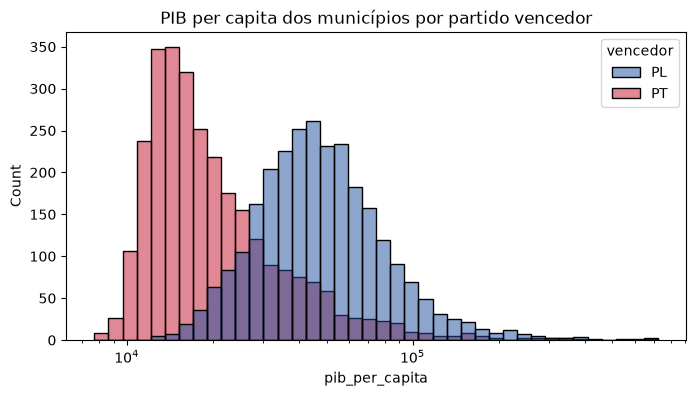

In [15]:
# Distribuição do PIB per capita (escala log: poucos municípios têm PIB muito alto)
plt.figure(figsize=(8, 4))
sns.histplot(data=base, x="pib_per_capita", hue="vencedor", palette={"PT": "#c4122d", "PL": "#1d4e9e"}, log_scale=True, bins=40)
plt.title("PIB per capita dos municípios por partido vencedor")
plt.show()

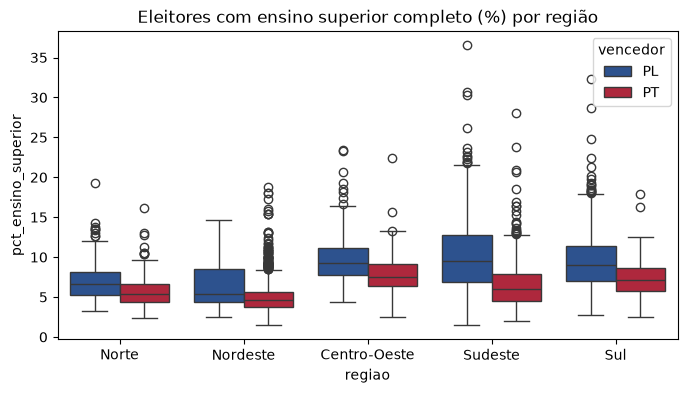

In [16]:
# Escolaridade do eleitorado por partido vencedor
plt.figure(figsize=(8, 4))
sns.boxplot(data=base, x="regiao", y="pct_ensino_superior", hue="vencedor", palette={"PT": "#c4122d", "PL": "#1d4e9e"})
plt.title("Eleitores com ensino superior completo (%) por região")
plt.show()

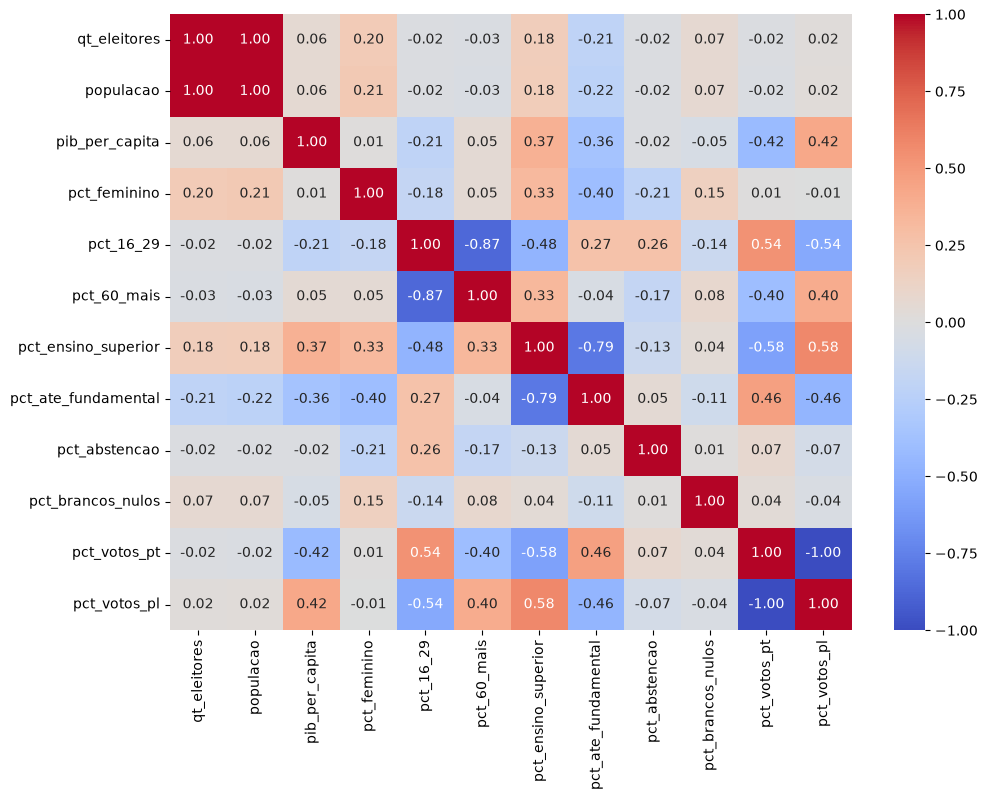

In [17]:
# Correlação entre os indicadores (sem códigos, coordenadas e ano)
indicadores = base.select_dtypes(include=["float64", "int64"]).drop(columns=["ano", "cd_municipio", "latitude", "longitude"])
plt.figure(figsize=(11, 8))
sns.heatmap(indicadores.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.show()

## Resumo do tratamento

1. Leitura dos arquivos brutos do TSE (zip, latin-1, `;`).
2. Filtro das linhas: 2º turno, presidente, sem o exterior.
3. Remoção dos campos que não são usados (`drop`).
4. Verificação de ausentes e duplicados (`isnull`, `duplicated`).
5. Agrupamento das zonas por município (`groupby`) e cálculo dos percentuais.
6. Junção com o perfil do eleitorado e com o IBGE (`merge`), remoção de ausentes (`dropna`) e conferência do alvo (`value_counts`).